# Milestone 1 – Reproduce: Cropped ShallowFBCSPNet on BCIC IV 2a

By default this notebook only **loads the results stored in `results/`** and shows the tables and
confusion matrices (no training, runs in seconds).

To retrain everything, set `RERUN = True` (GPU runtime recommended, ~30 min per 9-subject run on a
T4, ~1–1.5 h on CPU). New results are then written to Google Drive, finished subjects are skipped
after a disconnect.

In [1]:
RERUN = False

import os, sys, subprocess

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not os.path.exists('/content/Deep_Learning_Project'):
        !git clone -q https://github.com/Semih2341/Deep_Learning_Project.git /content/Deep_Learning_Project
    %cd /content/Deep_Learning_Project
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

RESULTS_DIR = 'results'
DATA_DIR = None
if RERUN:
    !pip install -q -r requirements.txt
    if IN_COLAB:
        from google.colab import drive
        drive.mount('/content/drive')
        DATA_DIR = '/content/drive/MyDrive/bci_mi_decoding/mne_data'
        RESULTS_DIR = '/content/drive/MyDrive/bci_mi_decoding/results'
    else:
        RESULTS_DIR = 'results_rerun'

## Training (only if `RERUN = True`)

1. Subject 3, tutorial setting (target ≈ 83.7 %)
2. All subjects, `tutorial` mode (test session used for early stopping, as in the example)
3. All subjects, `clean` mode, 3 seeds (fixed 100 epochs, test session only for evaluation)
4. All subjects, `clean` mode, 0–38 Hz band (paper setting, target 73.7 %)

In [2]:
def run(*args):
    cmd = [sys.executable, 'src/reproduce.py', '--out-dir', RESULTS_DIR, '--epochs', '100', *args]
    if DATA_DIR:
        cmd += ['--data-dir', DATA_DIR]
    subprocess.run(cmd, check=True)

if RERUN:
    run('--subjects', '3', '--mode', 'tutorial')
    run('--subjects', 'all', '--mode', 'tutorial')
    for seed in ['20200220', '1', '2']:
        run('--subjects', 'all', '--mode', 'clean', '--seed', seed)
    run('--subjects', 'all', '--mode', 'clean', '--low-cut', '0')

## Results

In [3]:
from IPython.display import Markdown, display

subprocess.run([sys.executable, 'src/summarize.py', '--results-dir', RESULTS_DIR],
               check=True, stdout=subprocess.DEVNULL)
display(Markdown(open(f'{RESULTS_DIR}/summary.md').read()))

### mode = `clean`, band = 0-38 Hz, seed = 20200220

| Subject | Test acc (%) | Train acc (%) | Selected epoch | Epochs run |
|---|---|---|---|---|
| 1 | 80.21 | 100.00 | 100 | 100 |
| 2 | 48.61 | 100.00 | 100 | 100 |
| 3 | 89.58 | 100.00 | 100 | 100 |
| 4 | 64.93 | 100.00 | 100 | 100 |
| 5 | 55.90 | 100.00 | 100 | 100 |
| 6 | 59.72 | 100.00 | 100 | 100 |
| 7 | 87.85 | 100.00 | 100 | 100 |
| 8 | 81.25 | 100.00 | 100 | 100 |
| 9 | 75.69 | 100.00 | 100 | 100 |
| **Mean ± std** | **71.53 ± 14.71** | 100.00 | | |

Subject 3: 89.58% (target 83.7%)  
Mean over 9 subjects: 71.53% (paper, same band: 73.7%)

### mode = `clean`, band = 4-38 Hz, seed = 1

| Subject | Test acc (%) | Train acc (%) | Selected epoch | Epochs run |
|---|---|---|---|---|
| 1 | 80.21 | 100.00 | 100 | 100 |
| 2 | 44.10 | 100.00 | 100 | 100 |
| 3 | 84.38 | 100.00 | 100 | 100 |
| 4 | 66.67 | 100.00 | 100 | 100 |
| 5 | 59.38 | 100.00 | 100 | 100 |
| 6 | 53.47 | 100.00 | 100 | 100 |
| 7 | 87.85 | 100.00 | 100 | 100 |
| 8 | 75.69 | 100.00 | 100 | 100 |
| 9 | 80.56 | 100.00 | 100 | 100 |
| **Mean ± std** | **70.25 ± 15.17** | 100.00 | | |

Subject 3: 84.38% (target 83.7%)  
Mean over 9 subjects: 70.25% (paper, same band: 71.9%)

### mode = `clean`, band = 4-38 Hz, seed = 2

| Subject | Test acc (%) | Train acc (%) | Selected epoch | Epochs run |
|---|---|---|---|---|
| 1 | 78.47 | 100.00 | 100 | 100 |
| 2 | 44.79 | 100.00 | 100 | 100 |
| 3 | 83.68 | 100.00 | 100 | 100 |
| 4 | 69.10 | 100.00 | 100 | 100 |
| 5 | 59.03 | 100.00 | 100 | 100 |
| 6 | 52.08 | 100.00 | 100 | 100 |
| 7 | 87.15 | 100.00 | 100 | 100 |
| 8 | 76.04 | 100.00 | 100 | 100 |
| 9 | 80.90 | 100.00 | 100 | 100 |
| **Mean ± std** | **70.14 ± 14.94** | 100.00 | | |

Subject 3: 83.68% (target 83.7%)  
Mean over 9 subjects: 70.14% (paper, same band: 71.9%)

### mode = `clean`, band = 4-38 Hz, seed = 20200220

| Subject | Test acc (%) | Train acc (%) | Selected epoch | Epochs run |
|---|---|---|---|---|
| 1 | 80.56 | 100.00 | 100 | 100 |
| 2 | 43.06 | 100.00 | 100 | 100 |
| 3 | 84.38 | 100.00 | 100 | 100 |
| 4 | 66.67 | 100.00 | 100 | 100 |
| 5 | 59.72 | 100.00 | 100 | 100 |
| 6 | 54.17 | 100.00 | 100 | 100 |
| 7 | 86.46 | 100.00 | 100 | 100 |
| 8 | 76.04 | 100.00 | 100 | 100 |
| 9 | 78.47 | 100.00 | 100 | 100 |
| **Mean ± std** | **69.95 ± 14.96** | 100.00 | | |

Subject 3: 84.38% (target 83.7%)  
Mean over 9 subjects: 69.95% (paper, same band: 71.9%)

### mode = `tutorial`, band = 4-38 Hz, seed = 20200220

| Subject | Test acc (%) | Train acc (%) | Selected epoch | Epochs run |
|---|---|---|---|---|
| 1 | 81.94 | 100.00 | 42 | 52 |
| 2 | 46.53 | 78.82 | 11 | 21 |
| 3 | 81.60 | 97.57 | 14 | 24 |
| 4 | 63.54 | 92.71 | 13 | 23 |
| 5 | 49.31 | 82.29 | 18 | 28 |
| 6 | 49.65 | 82.99 | 11 | 21 |
| 7 | 85.76 | 100.00 | 33 | 43 |
| 8 | 77.43 | 99.65 | 32 | 42 |
| 9 | 79.51 | 98.96 | 21 | 31 |
| **Mean ± std** | **68.36 ± 16.13** | 92.55 | | |

Subject 3: 81.60% (target 83.7%)  
Mean over 9 subjects: 68.36% (paper, same band: 71.9%)

### Across seeds

| Mode | Band | Seeds | Mean acc (%) over seeds | Subject 3 (%) |
|---|---|---|---|---|
| clean | 0-38 Hz | 1 | 71.53 | 89.58 |
| clean | 4-38 Hz | 3 | 70.11 ± 0.16 | 84.14 ± 0.40 |
| tutorial | 4-38 Hz | 1 | 68.36 | 81.60 |


## Confusion matrices (all subjects pooled, seed 20200220, 4–38 Hz)

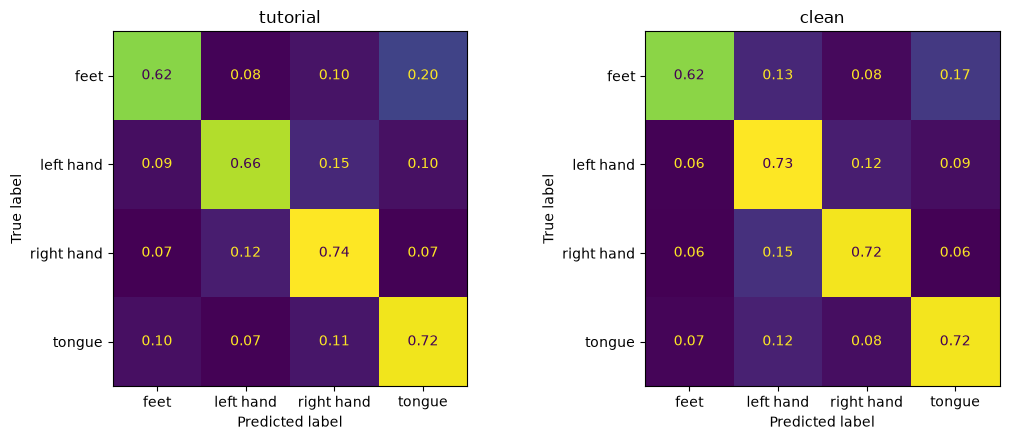

In [4]:
import json, glob
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

classes = ['feet', 'left hand', 'right hand', 'tongue']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, mode in zip(axes, ['tutorial', 'clean']):
    y_true, y_pred = [], []
    for f in sorted(glob.glob(f'{RESULTS_DIR}/{mode}_seed20200220/subject_*.json')):
        r = json.load(open(f))
        y_true += r['y_true']
        y_pred += r['y_pred']
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=classes, normalize='true',
        values_format='.2f', ax=ax, colorbar=False)
    ax.set_title(mode)
plt.tight_layout()
plt.show()